# SC5002 Lab Assignment 2 — K-Means Clustering and Neural Networks
Exercises 1–2: K-Means on customer data and on interlocking circles.  
Exercise 3: a small neural network (from Tutorial 7) that tells the vowels in *head* and *had* apart.

Run all cells top to bottom (**Runtime → Run all**). Figures are shown inline and saved to `figs/`. Exercise 3 trains a few small PyTorch networks (under a minute; PyTorch is pre-installed in Colab).

## Setup

In [ ]:
!pip install -q pyreadr
# Hillenbrand et al. (1995) vowel data, from the CRAN phonTools package
!wget -q -O h95.rda https://raw.githubusercontent.com/cran/phonTools/master/data/h95.rda
!ls -l h95.rda

-rw-r--r-- 1 root root 17602 Oct 30 10:35 h95.rda


---
# Exercises 1 & 2 — K-Means

In [ ]:
"""SC5002 Lab Assignment 2 - Exercises 1 & 2 (K-Means)."""
import json
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

OUT = "figs"
import os; os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"font.size": 8, "axes.titlesize": 9, "figure.dpi": 200})
res = {}

## Exercise 1 — Customer segmentation
### 1.1 K-Means with k = 3 and k = 5

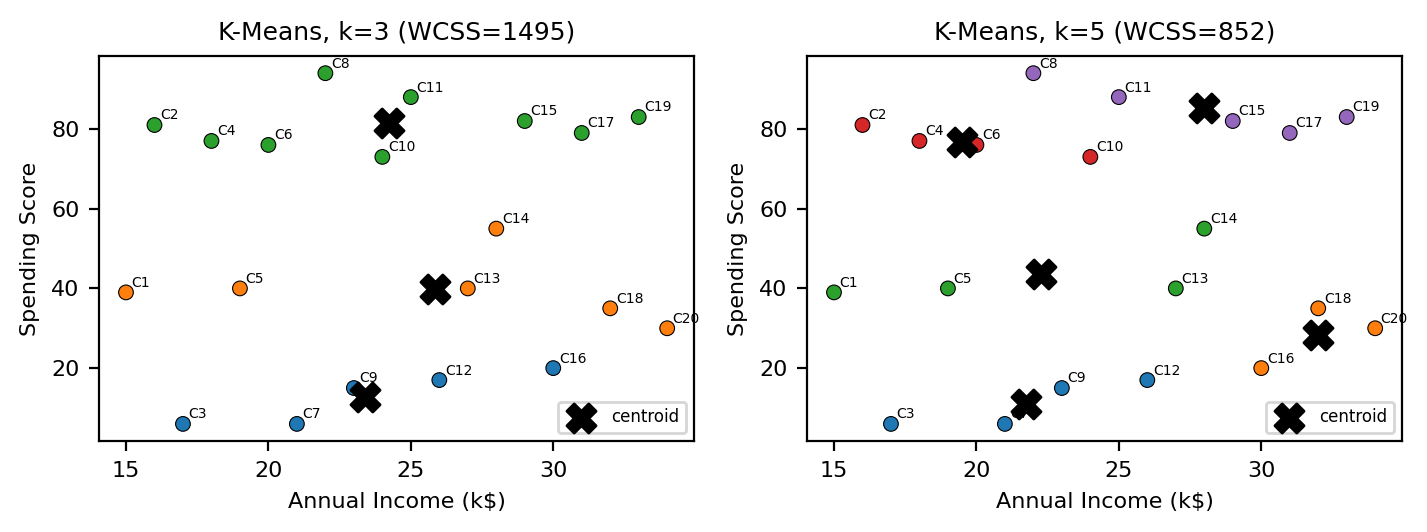

k=3  WCSS=1495.44
  cluster 0  centroid=[23.4, 12.8]  members=['C3', 'C7', 'C9', 'C12', 'C16']
  cluster 1  centroid=[25.83, 39.83]  members=['C1', 'C5', 'C13', 'C14', 'C18', 'C20']
  cluster 2  centroid=[24.22, 81.44]  members=['C2', 'C4', 'C6', 'C8', 'C10', 'C11', 'C15', 'C17', 'C19']
k=5  WCSS=851.72
  cluster 0  centroid=[21.75, 11.0]  members=['C3', 'C7', 'C9', 'C12']
  cluster 1  centroid=[32.0, 28.33]  members=['C16', 'C18', 'C20']
  cluster 2  centroid=[22.25, 43.5]  members=['C1', 'C5', 'C13', 'C14']
  cluster 3  centroid=[19.5, 76.75]  members=['C2', 'C4', 'C6', 'C10']
  cluster 4  centroid=[28.0, 85.2]  members=['C8', 'C11', 'C15', 'C17', 'C19']


In [ ]:
# Exercise 1!
X = np.array([[15,39],[16,81],[17,6],[18,77],[19,40],[20,76],[21,6],[22,94],[23,15],[24,73],
              [25,88],[26,17],[27,40],[28,55],[29,82],[30,20],[31,79],[32,35],[33,83],[34,30]], float)
names = [f"C{i}" for i in range(1, 21)]

def fit(k, seed=42, n_init=10):
    km = KMeans(n_clusters=k, n_init=n_init, random_state=seed).fit(X)
    # relabel clusters in order of centroid spending score so labels are readable
    order = np.argsort(km.cluster_centers_[:, 1])
    remap = {old: new for new, old in enumerate(order)}
    lab = np.array([remap[l] for l in km.labels_])
    return lab, km.cluster_centers_[order], km.inertia_

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7))
for ax, k in zip(axes, [3, 5]):
    lab, C, w = fit(k)
    res[f"k{k}"] = {"labels": lab.tolist(), "centroids": np.round(C, 2).tolist(), "wcss": round(w, 2),
                    "members": {int(c): [names[i] for i in np.where(lab == c)[0]] for c in range(k)}}
    ax.scatter(X[:, 0], X[:, 1], c=lab, cmap="tab10", vmin=0, vmax=9, s=28, edgecolor="k", lw=.4)
    ax.scatter(C[:, 0], C[:, 1], marker="X", s=110, c="k", label="centroid")

    for i, n in enumerate(names):
        ax.annotate(n, X[i], fontsize=5, xytext=(2, 2), textcoords="offset points")
    ax.set(title=f"K-Means, k={k} (WCSS={w:.0f})", xlabel="Annual Income (k$)", ylabel="Spending Score")
    ax.legend(loc="lower right", fontsize=6)
fig.tight_layout(); fig.savefig(f"{OUT}/ex1_k3_k5.png"); plt.show()

for k in [3, 5]:
    print(f"k={k}  WCSS={res[f'k{k}']['wcss']}")
    for c, mem in res[f'k{k}']['members'].items():
        print(f"  cluster {c}  centroid={res[f'k{k}']['centroids'][int(c)]}  members={mem}")

### 1.2 Elbow method

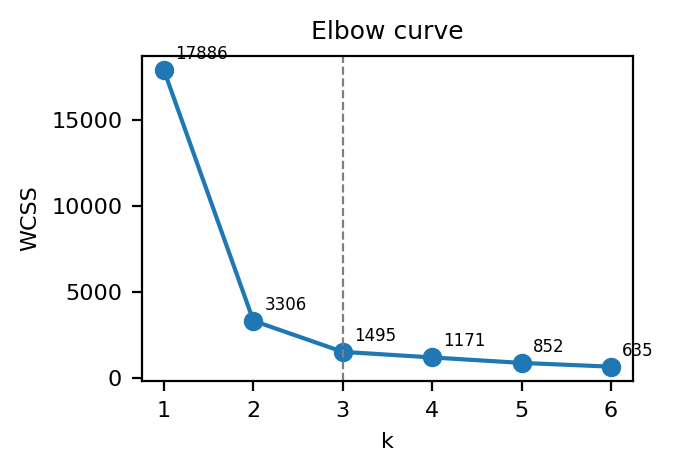

WCSS k=1..6: [17886.2, 3306.0, 1495.44, 1170.94, 851.72, 635.05]
% drop per extra cluster: [81.5, 54.8, 21.7, 27.3, 25.4]
Chosen elbow k = 3 | geometric knee detector = 2


In [ ]:
# Elbow
wcss = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_ for k in range(1, 7)]
res["wcss"] = [round(w, 2) for w in wcss]
res["wcss_drop_pct"] = [round(100 * (wcss[i-1] - wcss[i]) / wcss[i-1], 1) for i in range(1, 6)]
# "kneedle"-style: max distance from the chord joining k=1 and k=6
ks = np.arange(1, 7); y = np.array(wcss)
p1, p2 = np.array([1, y[0]]), np.array([6, y[-1]])
xn, yn = (ks - 1) / 5, (y - y.min()) / (y.max() - y.min())
d = np.abs((0 - 1) * xn - (1 - 0) * (1 - yn) + 0) / np.sqrt(2)  # line from (0,1) to (1,0)
d = np.abs(xn + yn - 1) / np.sqrt(2)
res["kneedle_k"] = int(ks[np.argmax(d)])  # =2, dominated by the huge k=1 WCSS
# Chosen elbow: last k with a >50% WCSS drop; after k=3 the drops level off at ~22-27%
res["elbow_k"] = 3

fig, ax = plt.subplots(figsize=(3.4, 2.4))
ax.plot(ks, wcss, "o-", c="#1f77b4")
for k_, w_ in zip(ks, wcss): ax.annotate(f"{w_:.0f}", (k_, w_), xytext=(4, 4), textcoords="offset points", fontsize=6)
ax.axvline(res["elbow_k"], ls="--", c="grey", lw=.8)
ax.set(title="Elbow curve", xlabel="k", ylabel="WCSS"); fig.tight_layout(); fig.savefig(f"{OUT}/ex1_elbow.png"); plt.show()

print('WCSS k=1..6:', res['wcss'])
print('% drop per extra cluster:', res['wcss_drop_pct'])
print('Chosen elbow k =', res['elbow_k'], '| geometric knee detector =', res['kneedle_k'])

### 1.3 Sensitivity to initialisation
Single random initialisation (`init='random', n_init=1`), seeds 0–9, compared with the best of 50 restarts using the Adjusted Rand Index.

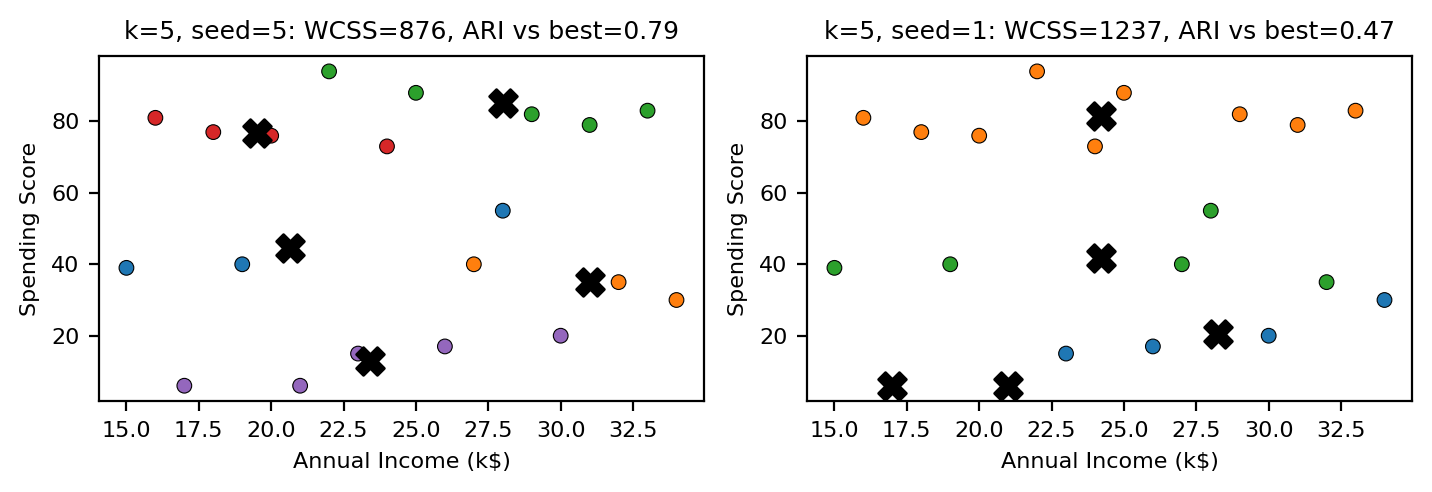

k=3: best WCSS=1495.44, distinct solutions over 10 seeds=3
    {'seed': 0, 'wcss': 2913.52, 'iters': 3, 'ari_vs_best': 0.37, 'sizes': [3, 7, 10]}
    {'seed': 1, 'wcss': 1495.44, 'iters': 3, 'ari_vs_best': 1.0, 'sizes': [5, 6, 9]}
    {'seed': 2, 'wcss': 1495.44, 'iters': 3, 'ari_vs_best': 1.0, 'sizes': [5, 6, 9]}
    {'seed': 3, 'wcss': 2780.8, 'iters': 2, 'ari_vs_best': 0.359, 'sizes': [5, 5, 10]}
    {'seed': 4, 'wcss': 1495.44, 'iters': 4, 'ari_vs_best': 1.0, 'sizes': [5, 6, 9]}
    {'seed': 5, 'wcss': 1495.44, 'iters': 4, 'ari_vs_best': 1.0, 'sizes': [5, 6, 9]}
    {'seed': 6, 'wcss': 1495.44, 'iters': 3, 'ari_vs_best': 1.0, 'sizes': [5, 6, 9]}
    {'seed': 7, 'wcss': 1495.44, 'iters': 3, 'ari_vs_best': 1.0, 'sizes': [5, 6, 9]}
    {'seed': 8, 'wcss': 1495.44, 'iters': 3, 'ari_vs_best': 1.0, 'sizes': [5, 6, 9]}
    {'seed': 9, 'wcss': 2780.8, 'iters': 3, 'ari_vs_best': 0.359, 'sizes': [5, 5, 10]}
k=5: best WCSS=851.72, distinct solutions over 10 seeds=9
    {'seed': 0, 'wcss': 992

In [ ]:
# Sensitivity to initialisation: single random init (init='random', n_init=1), 10 seeds
sens = {}
for k in [3, 5]:
    rows = []
    best = KMeans(n_clusters=k, n_init=50, random_state=0).fit(X)
    for s in range(10):
        km = KMeans(n_clusters=k, init="random", n_init=1, random_state=s).fit(X)
        rows.append({"seed": s, "wcss": round(km.inertia_, 2), "iters": int(km.n_iter_),
                     "ari_vs_best": round(adjusted_rand_score(best.labels_, km.labels_), 3),
                     "sizes": sorted(np.bincount(km.labels_).tolist())})
    sens[k] = {"best_wcss": round(best.inertia_, 2), "runs": rows,
               "n_distinct_wcss": len({r["wcss"] for r in rows})}
res["sensitivity"] = sens

# figure: two different seeds for k=5 with different solutions
runs = sens[5]["runs"]
lo = min(runs, key=lambda r: r["wcss"]); hi = max(runs, key=lambda r: r["wcss"])
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.5))
for ax, r in zip(axes, [lo, hi]):
    km = KMeans(n_clusters=5, init="random", n_init=1, random_state=r["seed"]).fit(X)
    ax.scatter(X[:, 0], X[:, 1], c=km.labels_, cmap="tab10", vmin=0, vmax=9, s=28, edgecolor="k", lw=.4)
    ax.scatter(*km.cluster_centers_.T, marker="X", s=100, c="k")
    ax.set(title=f"k=5, seed={r['seed']}: WCSS={r['wcss']:.0f}, ARI vs best={r['ari_vs_best']:.2f}",
           xlabel="Annual Income (k$)", ylabel="Spending Score")
fig.tight_layout(); fig.savefig(f"{OUT}/ex1_seeds.png"); plt.show()

for k in [3, 5]:
    print(f"k={k}: best WCSS={sens[k]['best_wcss']}, distinct solutions over 10 seeds={sens[k]['n_distinct_wcss']}")
    for r_ in sens[k]['runs']: print('   ', r_)

## Exercise 2 — Interlocking circles

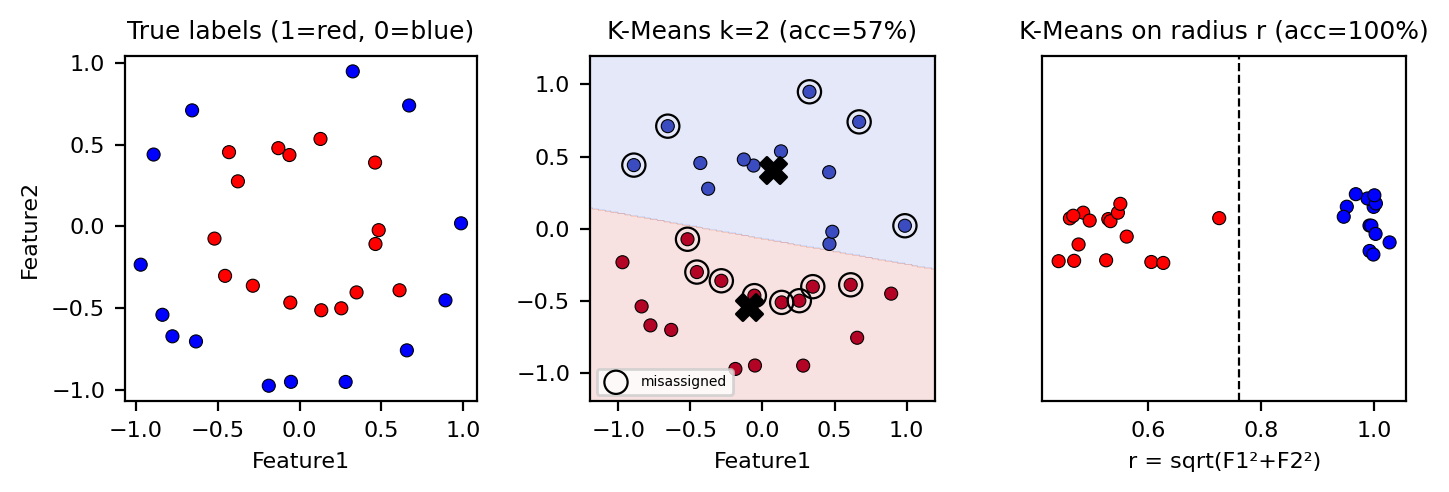

Radius ranges: {'label1': [np.float64(0.442), np.float64(0.726)], 'label0': [np.float64(0.947), np.float64(1.028)]}
K-Means k=2: {'acc_best_mapping': np.float64(0.567), 'ari': -0.017, 'centroids': [[0.075, 0.408], [-0.094, -0.544]], 'wcss': 10.929}
Accuracy range over 50 seeds: [np.float64(0.5), np.float64(0.633)]
K-Means on radius r, accuracy: 1.0


In [ ]:
# ------------------------------------------------------------------ Exercise 2
D = np.array([
 [0.1331,-0.5126,1],[0.4648,-0.1070,1],[-0.5205,-0.0741,1],[0.4625,0.3913,1],[-0.9720,-0.2337,0],
 [-0.8390,-0.5404,0],[0.3491,-0.4034,1],[-0.4556,-0.3020,1],[0.2823,-0.9513,0],[0.9885,0.0195,0],
 [-0.0522,-0.9507,0],[-0.4315,0.4549,1],[0.1283,0.5358,1],[-0.0563,-0.4657,1],[0.4846,-0.0224,1],
 [-0.1881,-0.9745,0],[0.3259,0.9493,0],[-0.8930,0.4404,0],[-0.7778,-0.6721,0],[0.6570,-0.7580,0],
 [-0.0618,0.4373,1],[0.6709,0.7405,0],[-0.6336,-0.7034,0],[-0.2857,-0.3625,1],[-0.1296,0.4794,1],
 [0.2557,-0.5007,1],[-0.6574,0.7107,0],[0.8932,-0.4518,0],[-0.3771,0.2763,1],[0.6122,-0.3904,1]])
P, y2 = D[:, :2], D[:, 2].astype(int)
r = np.hypot(P[:, 0], P[:, 1])
res["ex2_radius"] = {"label1": [round(r[y2 == 1].min(), 3), round(r[y2 == 1].max(), 3)],
                     "label0": [round(r[y2 == 0].min(), 3), round(r[y2 == 0].max(), 3)]}

km2 = KMeans(n_clusters=2, n_init=10, random_state=42).fit(P)
pred = km2.labels_
acc = max((pred == y2).mean(), (1 - pred == y2).mean())
res["ex2_kmeans"] = {"acc_best_mapping": round(acc, 3), "ari": round(adjusted_rand_score(y2, pred), 3),
                     "centroids": np.round(km2.cluster_centers_, 3).tolist(), "wcss": round(km2.inertia_, 3)}
# sanity: across many seeds
accs = []
for s in range(50):
    p_ = KMeans(n_clusters=2, n_init=1, init="random", random_state=s).fit(P).labels_
    accs.append(max((p_ == y2).mean(), (1 - p_ == y2).mean()))
res["ex2_kmeans_acc_range_50seeds"] = [round(min(accs), 3), round(max(accs), 3)]

# Fix: K-Means on the radius feature (polar transform)
kmr = KMeans(n_clusters=2, n_init=10, random_state=42).fit(r.reshape(-1, 1))
pr = kmr.labels_
res["ex2_radius_kmeans_acc"] = round(max((pr == y2).mean(), (1 - pr == y2).mean()), 3)

fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.5))
cols = np.where(y2 == 1, "red", "blue")
axes[0].scatter(P[:, 0], P[:, 1], c=cols, s=22, edgecolor="k", lw=.4)
axes[0].set(title="True labels (1=red, 0=blue)", aspect="equal", xlabel="Feature1", ylabel="Feature2")
# K-Means result with Voronoi boundary
gx, gy = np.meshgrid(np.linspace(-1.2, 1.2, 300), np.linspace(-1.2, 1.2, 300))
Z = km2.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
axes[1].contourf(gx, gy, Z, alpha=.15, cmap="coolwarm")
axes[1].scatter(P[:, 0], P[:, 1], c=pred, cmap="coolwarm", s=22, edgecolor="k", lw=.4)
wrong = pred != y2 if (pred == y2).mean() >= .5 else (1 - pred) != y2
axes[1].scatter(P[wrong, 0], P[wrong, 1], facecolor="none", edgecolor="k", s=70, lw=.8, label="misassigned")
axes[1].scatter(*km2.cluster_centers_.T, marker="X", s=90, c="k")
axes[1].set(title=f"K-Means k=2 (acc={acc:.0%})", aspect="equal", xlabel="Feature1")
axes[1].legend(fontsize=5, loc="lower left")
axes[2].scatter(r, np.zeros_like(r) + np.random.default_rng(0).uniform(-.1, .1, len(r)), c=cols, s=22, edgecolor="k", lw=.4)
axes[2].axvline(np.mean(kmr.cluster_centers_), ls="--", c="k", lw=.8)
axes[2].set(title=f"K-Means on radius r (acc={res['ex2_radius_kmeans_acc']:.0%})", xlabel="r = sqrt(F1²+F2²)", yticks=[], ylim=(-.5, .5))
fig.tight_layout(); fig.savefig(f"{OUT}/ex2.png"); plt.show()

print('Radius ranges:', res['ex2_radius'])
print('K-Means k=2:', res['ex2_kmeans'])
print('Accuracy range over 50 seeds:', res['ex2_kmeans_acc_range_50seeds'])
print('K-Means on radius r, accuracy:', res['ex2_radius_kmeans_acc'])

In [ ]:
json.dump(res, open("results_ex12.json", "w"), indent=1)

---
# Exercise 3 — Telling "head" and "had" apart with a neural network
Two vowels from the Hillenbrand et al. (1995) dataset: /ɛ/ as in *head* (label 0) and /æ/ as in *had* (label 1). The model, loss, optimiser, split and training loop follow Tutorial 7.

In [ ]:
"""SC5002 Lab Assignment 2 - Exercise 3: telling apart the vowels in "head" and "had"
Dataset: Hillenbrand, Getty, Clark & Wheeler (1995) vowel recordings (h95 in the phonTools R package).
The neural network code follows Tutorial 7 (ANN class, BCELoss, Adam, 500 epochs, 60/20/20 split).
"""
import json, os, warnings
import numpy as np, pandas as pd, pyreadr
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 8, "axes.titlesize": 9, "figure.dpi": 200})
os.makedirs("figs", exist_ok=True)
res = {}

## 3.1 Dataset and exploration

[[ 257.  238.  630. 2423. 3166.]
 [ 184.  214.  713. 2095. 3129.]
 [ 359.  286.  829. 2495. 3218.]] [1 0 1]


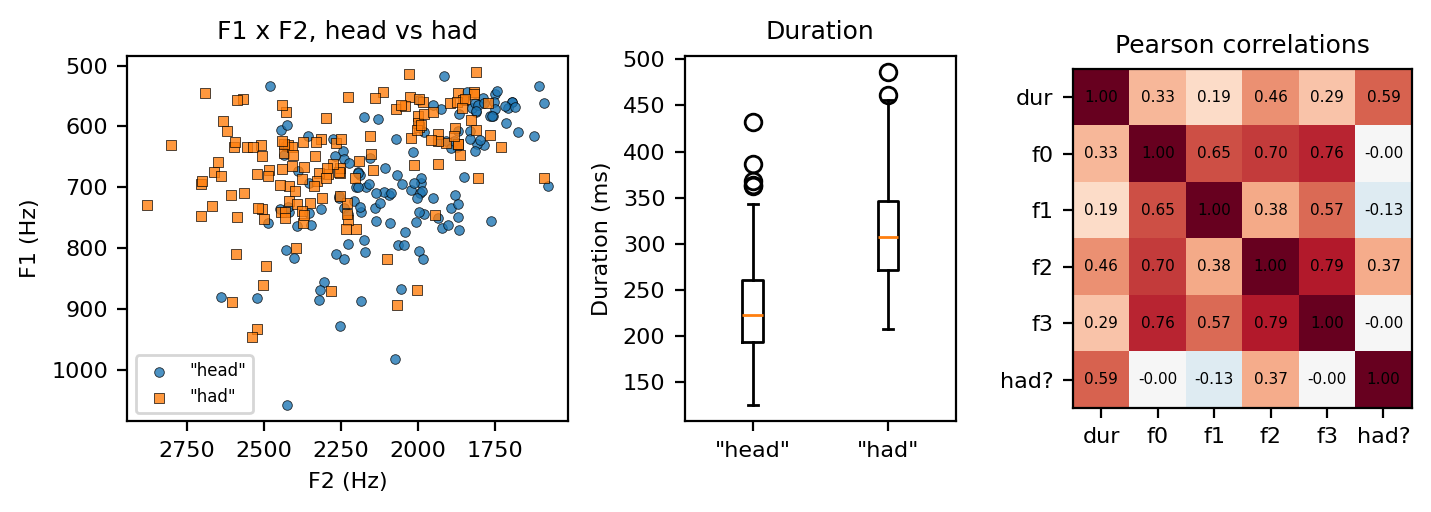

278 recordings {'had': 139, 'head': 139} | speakers: {'b': 27, 'g': 19, 'm': 45, 'w': 48} | missing: 0


dur           f0           f1             f2             f3       
       mean   std   mean   std   mean    std    mean    std    mean    std
word                                                                      
had   310.0  55.0  191.0  50.0  663.0   87.0  2257.0  279.0  2952.0  341.0
head  230.0  53.0  191.0  49.0  686.0  101.0  2050.0  238.0  2954.0  333.0

In [ ]:
# ----------------------------------------------------------------------------- 1. Dataset
d = pyreadr.read_r("h95.rda")["h95"].copy()
d["vowel"] = d["vowel"].astype(str)
d["type"] = d["type"].astype(str)
# keep only two vowels: /ɛ/ as in "head" (label 0) and /æ/ as in "had" (label 1)
d = d[d.vowel.isin(["E", "{"])].reset_index(drop=True)
d["word"] = d.vowel.map({"E": "head", "{": "had"})
d["label"] = (d.vowel == "{").astype(int)
FEATS = ["dur", "f0", "f1", "f2", "f3"]
X = d[FEATS].values.astype(float)
y = d["label"].values
print(X[0:3], y[0:3])  # first three recordings and their labels, as in Tutorial 7

res["n"] = len(d)
res["n_per_word"] = d.word.value_counts().to_dict()
res["speakers_by_type"] = (d.groupby("type").speaker.nunique()).to_dict()
res["missing"] = int(d[FEATS].isna().sum().sum())
res["summary_by_word"] = {w: d[d.word == w][FEATS].agg(["mean", "std"]).round(0).to_dict() for w in ["head", "had"]}
res["corr"] = d[FEATS + ["label"]].corr().round(2).to_dict()

# EDA figure: F2 vs F1 scatter (inverted, like a vowel chart), duration by word, correlation heatmap
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.6), gridspec_kw={"width_ratios": [1.3, .8, 1]})
for w, c_, mk in [("head", "#1f77b4", "o"), ("had", "#ff7f0e", "s")]:
    s_ = d[d.word == w]
    axes[0].scatter(s_.f2, s_.f1, s=12, color=c_, marker=mk, edgecolor="k", lw=.3, alpha=.8, label=f'"{w}"')
axes[0].invert_xaxis(); axes[0].invert_yaxis()
axes[0].set(xlabel="F2 (Hz)", ylabel="F1 (Hz)", title="F1 x F2, head vs had")
axes[0].legend(fontsize=6)
axes[1].boxplot([d[d.word == "head"].dur, d[d.word == "had"].dur])
axes[1].set(xticks=[1, 2], xticklabels=['"head"', '"had"'], ylabel="Duration (ms)", title="Duration")
cols = FEATS + ["label"]; lab_ = ["dur", "f0", "f1", "f2", "f3", "had?"]
c = d[cols].corr().values
axes[2].imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
axes[2].set(xticks=range(6), yticks=range(6), xticklabels=lab_, yticklabels=lab_, title="Pearson correlations")
for a in range(6):
    for b in range(6): axes[2].text(b, a, f"{c[a, b]:.2f}", ha="center", va="center", fontsize=5.5)
fig.tight_layout(); fig.savefig("figs/ex3_eda.png"); plt.show()

print(res['n'], 'recordings', res['n_per_word'], '| speakers:', res['speakers_by_type'], '| missing:', res['missing'])
d.groupby('word')[FEATS].agg(['mean', 'std']).round(0)

## 3.2 Split the data 60/20/20 (same as Tutorial 7) and standardise

In [ ]:
# ----------------------------------------------------------------------------- Split (same as Tutorial 7)
# Split dataset: 60% train, 20% val, 20% test
idx = np.arange(len(d))
idx_train, idx_temp = train_test_split(idx, test_size=0.4, random_state=42)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.5, random_state=42)
res["split"] = {"train": len(idx_train), "val": len(idx_val), "test": len(idx_test)}

def make_tensors(cols):
    """Standardise the chosen columns (using training-set statistics only) and convert to torch tensors.
    Formants are in the thousands of Hz and duration in the hundreds of ms, so they need to be put on the same scale."""
    ci = [FEATS.index(c_) for c_ in cols]
    sc = StandardScaler().fit(X[idx_train][:, ci])
    out = []
    for ix in (idx_train, idx_val, idx_test):
        out.append(torch.tensor(sc.transform(X[ix][:, ci]), dtype=torch.float32))
        out.append(torch.tensor(y[ix].reshape(-1, 1), dtype=torch.float32))
    return out, sc

res['split']

{'train': 166, 'val': 56, 'test': 56}

## 3.3 ANN model and training loop (Tutorial 7)
Same `ANN` class as the tutorial: one hidden layer of 4 ReLU neurons and 1 sigmoid output, trained with `BCELoss` and Adam (lr = 0.01) for 500 epochs. The only change is 5 inputs instead of 2. We also record the test loss, because the brief asks for training, validation and test losses.

In [ ]:
# ----------------------------------------------------------------------------- 2. ANN model (Tutorial 7)
class ANN(nn.Module):
    def __init__(self, n_inputs=5, n_hidden=4):
        super(ANN, self).__init__()
        self.hidden = nn.Linear(n_inputs, n_hidden)
        self.output = nn.Linear(n_hidden, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = torch.relu(self.hidden(x))  # use ReLU in hidden layer
        x = self.sigmoid(self.output(x))
        return x

EPOCHS = 500

# ----------------------------------------------------------------------------- 3. Training loop (Tutorial 7)
def train(cols=FEATS, n_hidden=4, lr=0.01, epochs=EPOCHS, seed=0):
    (X_train_t, y_train_t, X_val_t, y_val_t, X_test_t, y_test_t), sc = make_tensors(cols)
    torch.manual_seed(seed)
    model = ANN(n_inputs=len(cols), n_hidden=n_hidden)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    hist = {"train": [], "val": [], "test": [], "val_acc": []}
    for epoch in range(epochs):
        # Forward
        outputs = model(X_train_t)
        loss = criterion(outputs, y_train_t)
        # Backward
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # Record loss (we also record test loss, which the brief asks us to plot)
        hist["train"].append(loss.item())
        with torch.no_grad():
            val_outputs = model(X_val_t)
            hist["val"].append(criterion(val_outputs, y_val_t).item())
            hist["test"].append(criterion(model(X_test_t), y_test_t).item())
            hist["val_acc"].append(((val_outputs >= 0.5).float().eq(y_val_t).sum() / len(y_val_t)).item())
    sets = {"train": (X_train_t, y_train_t), "val": (X_val_t, y_val_t), "test": (X_test_t, y_test_t)}
    return model, hist, sets, sc

## 3.4 Train the main model and evaluate it (accuracy, confusion matrix, loss curves)

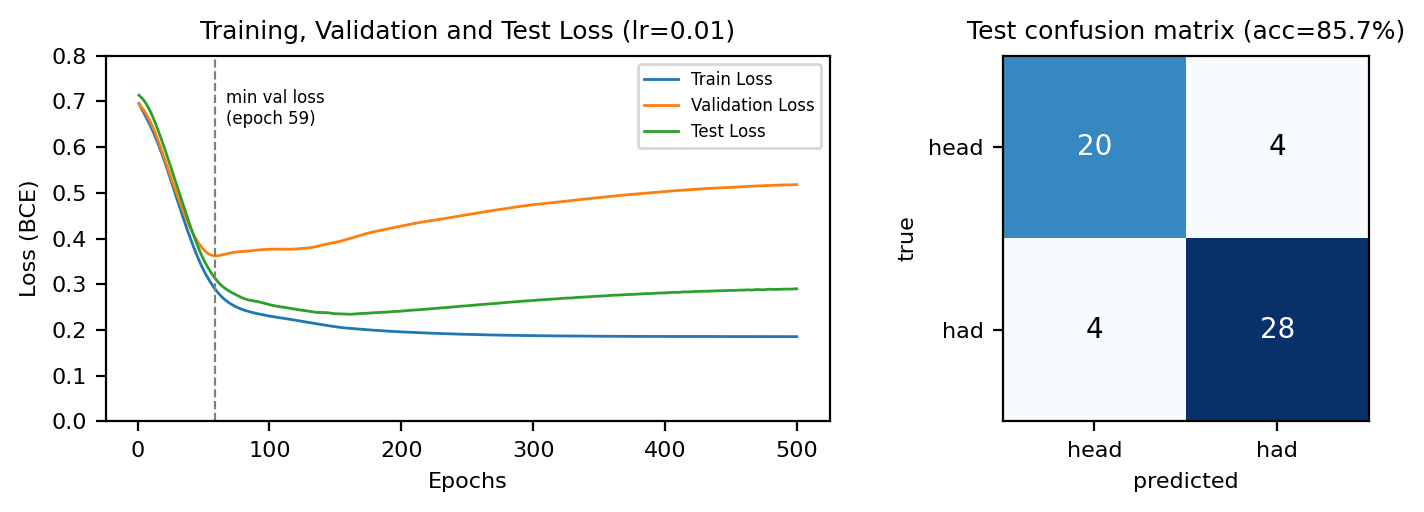

Main model: {
 "arch": "5-4-1",
 "params": 29,
 "epochs": 500,
 "lr": 0.01,
 "acc": {
  "train": 0.9157,
  "val": 0.8571,
  "test": 0.8571
 },
 "best_val_epoch": 59,
 "loss_at_best": {
  "train": 0.289,
  "val": 0.362,
  "test": 0.312
 },
 "loss_final": {
  "train": 0.186,
  "val": 0.518,
  "test": 0.29
 },
 "acc_if_stopped_early": {
  "train": 0.8916,
  "val": 0.8393,
  "test": 0.875
 }
}
Test confusion matrix [[head→head, head→had], [had→head, had→had]]: [[20, 4], [4, 28]]


In [ ]:
# ----------------------------------------------------------------------------- 4. Evaluate accuracy
def accuracy(model, X_t, y_t):
    with torch.no_grad():
        preds_cls = (model(X_t) >= 0.5).float()
        return (preds_cls.eq(y_t).sum() / len(y_t)).item()

def all_acc(model, sets):
    return {k: round(accuracy(model, *v), 4) for k, v in sets.items()}

model, H, sets, sc_main = train()
best_ep = int(np.argmin(H["val"])) + 1
res["main"] = {"arch": "5-4-1", "params": int(sum(p.numel() for p in model.parameters())), "epochs": EPOCHS, "lr": 0.01,
               "acc": all_acc(model, sets), "best_val_epoch": best_ep,
               "loss_at_best": {k: round(H[k][best_ep - 1], 3) for k in ["train", "val", "test"]},
               "loss_final": {k: round(H[k][-1], 3) for k in ["train", "val", "test"]}}
# what the same model would score if training had stopped at the best validation epoch
m_es, _, _, _ = train(epochs=best_ep)
res["main"]["acc_if_stopped_early"] = all_acc(m_es, sets)

with torch.no_grad():
    p_test = model(sets["test"][0]).numpy().ravel()
pred_test = (p_test >= 0.5).astype(int)
cm = confusion_matrix(y[idx_test], pred_test, labels=[0, 1])
res["confusion_test"] = cm.tolist()

# figure: loss curves + confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6), gridspec_kw={"width_ratios": [1.6, 1]})
ep = np.arange(1, EPOCHS + 1)
for k, c_, nm in zip(["train", "val", "test"], ["#1f77b4", "#ff7f0e", "#2ca02c"], ["Train Loss", "Validation Loss", "Test Loss"]):
    axes[0].plot(ep, H[k], c=c_, lw=1, label=nm)
axes[0].axvline(best_ep, ls="--", c="grey", lw=.8)
axes[0].text(best_ep + 8, .65, f"min val loss\n(epoch {best_ep})", fontsize=6)
axes[0].set(xlabel="Epochs", ylabel="Loss (BCE)", title="Training, Validation and Test Loss (lr=0.01)", ylim=(0, .8))
axes[0].legend(fontsize=6)
axes[1].imshow(cm, cmap="Blues")
axes[1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["head", "had"], yticklabels=["head", "had"],
            xlabel="predicted", ylabel="true", title=f"Test confusion matrix (acc={res['main']['acc']['test']:.1%})")
for a in range(2):
    for b in range(2):
        axes[1].text(b, a, cm[a, b], ha="center", va="center", fontsize=10, color="white" if cm[a, b] > cm.max() / 2 else "k")
fig.tight_layout(); fig.savefig("figs/ex3_main.png"); plt.show()

print('Main model:', json.dumps(res['main'], indent=1))
print('Test confusion matrix [[head→head, head→had], [had→head, had→had]]:', res['confusion_test'])

## 3.5 Ablation — learning rate (0.1, 0.01, 0.001)

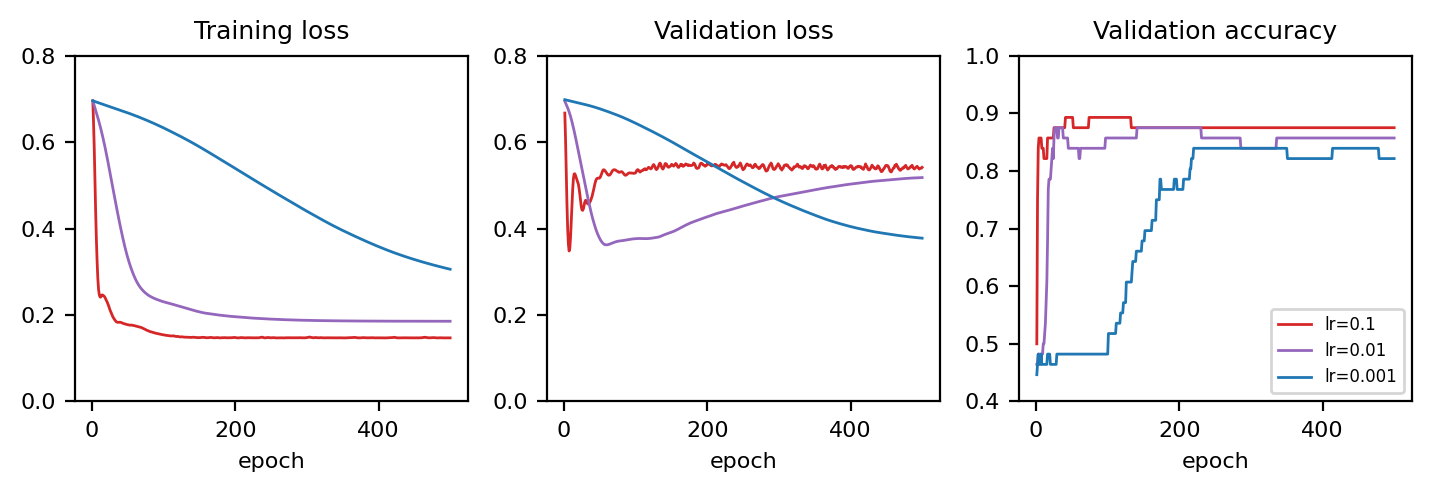

0.1 {'acc': {'train': 0.9458, 'val': 0.875, 'test': 0.8214}, 'best_ep': 7, 'min_val_loss': 0.348, 'final_val_loss': 0.542, 'final_train_loss': 0.147}
0.01 {'acc': {'train': 0.9157, 'val': 0.8571, 'test': 0.8571}, 'best_ep': 59, 'min_val_loss': 0.362, 'final_val_loss': 0.518, 'final_train_loss': 0.186}
0.001 {'acc': {'train': 0.8855, 'val': 0.8214, 'test': 0.8393}, 'best_ep': 500, 'min_val_loss': 0.378, 'final_val_loss': 0.378, 'final_train_loss': 0.306}


In [ ]:
# ----------------------------------------------------------------------------- 5. Ablation: learning rate
abl_lr = {}
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.5))
for lr_, c_ in zip([0.1, 0.01, 0.001], ["#d62728", "#9467bd", "#1f77b4"]):
    m_, h_, s_, _ = train(lr=lr_)
    abl_lr[str(lr_)] = {"acc": all_acc(m_, s_), "best_ep": int(np.argmin(h_["val"])) + 1,
                        "min_val_loss": round(min(h_["val"]), 3), "final_val_loss": round(h_["val"][-1], 3),
                        "final_train_loss": round(h_["train"][-1], 3)}
    axes[0].plot(ep, h_["train"], c=c_, lw=1, label=f"lr={lr_}")
    axes[1].plot(ep, h_["val"], c=c_, lw=1, label=f"lr={lr_}")
    axes[2].plot(ep, h_["val_acc"], c=c_, lw=1, label=f"lr={lr_}")
axes[0].set(title="Training loss", xlabel="epoch", ylim=(0, .8))
axes[1].set(title="Validation loss", xlabel="epoch", ylim=(0, .8))
axes[2].set(title="Validation accuracy", xlabel="epoch", ylim=(.4, 1)); axes[2].legend(fontsize=6)
fig.tight_layout(); fig.savefig("figs/ex3_lr.png"); plt.show()
res["ablation_lr"] = abl_lr

for k_, v_ in abl_lr.items(): print(k_, v_)

## 3.6 Ablation — number of hidden neurons

In [ ]:
# Ablation: number of hidden neurons (lr = 0.01)
abl_h = {}
for nh in [2, 4, 16, 64]:
    m_, h_, s_, _ = train(n_hidden=nh)
    abl_h[str(nh)] = {"acc": all_acc(m_, s_), "best_ep": int(np.argmin(h_["val"])) + 1,
                      "min_val_loss": round(min(h_["val"]), 3), "final_val_loss": round(h_["val"][-1], 3)}
res["ablation_hidden"] = abl_h

for k_, v_ in abl_h.items(): print(k_, v_)

2 {'acc': {'train': 0.8976, 'val': 0.8393, 'test': 0.875}, 'best_ep': 369, 'min_val_loss': 0.4, 'final_val_loss': 0.414}
4 {'acc': {'train': 0.9157, 'val': 0.8571, 'test': 0.8571}, 'best_ep': 59, 'min_val_loss': 0.362, 'final_val_loss': 0.518}
16 {'acc': {'train': 0.9819, 'val': 0.8571, 'test': 0.8036}, 'best_ep': 33, 'min_val_loss': 0.357, 'final_val_loss': 0.472}
64 {'acc': {'train': 1.0, 'val': 0.875, 'test': 0.8036}, 'best_ep': 47, 'min_val_loss': 0.354, 'final_val_loss': 0.502}


## 3.7 Ablation — inputs, and the decision boundary for F1 + F2 only (like the Tutorial 7 plot)

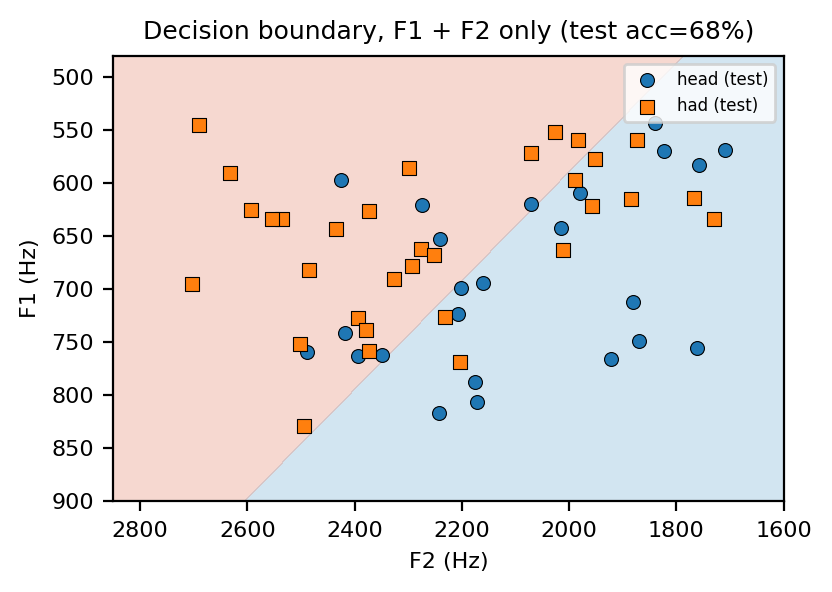

F1 + F2 only: {'acc': {'train': 0.6807, 'val': 0.8036, 'test': 0.6786}, 'best_ep': 107}
Duration + F1 + F2: {'acc': {'train': 0.8554, 'val': 0.8393, 'test': 0.7857}, 'best_ep': 271}


In [ ]:
# Ablation: inputs. Only F1 and F2 (2 inputs, like the 2 features in Tutorial 7) -> lets us draw the decision boundary
m2, h2, s2, sc2 = train(cols=["f1", "f2"])
res["ablation_f1f2"] = {"acc": all_acc(m2, s2), "best_ep": int(np.argmin(h2["val"])) + 1}
m3, h3, s3, _ = train(cols=["dur", "f1", "f2"])
res["ablation_dur_f1f2"] = {"acc": all_acc(m3, s3), "best_ep": int(np.argmin(h3["val"])) + 1}

# Decision boundary plot for the 2-input model (same idea as Tutorial 7, drawn in Hz)
f1g, f2g = np.meshgrid(np.linspace(480, 900, 250), np.linspace(1600, 2850, 250))
grid = sc2.transform(np.c_[f1g.ravel(), f2g.ravel()])
with torch.no_grad():
    Z = m2(torch.tensor(grid, dtype=torch.float32)).numpy().reshape(f1g.shape)
fig, ax = plt.subplots(figsize=(4.2, 3.0))
ax.contourf(f2g, f1g, Z, levels=[0, .5, 1], cmap=plt.cm.RdBu_r, alpha=0.3)
for lab, c_, mk, w in [(0, "#1f77b4", "o", "head"), (1, "#ff7f0e", "s", "had")]:
    ix = idx_test[y[idx_test] == lab]
    ax.scatter(d.f2.values[ix], d.f1.values[ix], s=25, color=c_, marker=mk, edgecolor="k", lw=.4, label=f"{w} (test)")
ax.invert_xaxis(); ax.invert_yaxis()
ax.set(xlabel="F2 (Hz)", ylabel="F1 (Hz)",
       title=f"Decision boundary, F1 + F2 only (test acc={res['ablation_f1f2']['acc']['test']:.0%})")
ax.legend(fontsize=6)
fig.tight_layout(); fig.savefig("figs/ex3_boundary.png"); plt.show()

print('F1 + F2 only:', res['ablation_f1f2'])
print('Duration + F1 + F2:', res['ablation_dur_f1f2'])

## 3.8 Case study — successes and failures

In [ ]:
# ----------------------------------------------------------------------------- 6. Case study (main model, test set)
dt = d.iloc[idx_test].copy()
dt["p_had"] = p_test.round(3)
dt["pred"] = np.where(pred_test == 1, "had", "head")
dt["correct"] = dt.pred == dt.word
dt["confidence"] = np.where(pred_test == 1, p_test, 1 - p_test).round(3)
grp = {"m": "Man", "w": "Woman", "b": "Boy", "g": "Girl"}
dt["who"] = dt.type.map(grp) + " " + dt.speaker.astype(int).astype(str)
keep = ["who", "word", "pred", "confidence", "dur", "f0", "f1", "f2", "f3"]
cases = {"right": dt[dt.correct].sort_values("confidence", ascending=False).head(3)[keep].to_dict(orient="records"),
         "wrong": dt[~dt.correct].sort_values("confidence", ascending=False)[keep].to_dict(orient="records")}
res["cases"] = cases
res["test_acc_by_group"] = dt.groupby("type").correct.mean().round(3).to_dict()
res["test_n_by_group"] = dt.type.value_counts().to_dict()

print('Test accuracy by speaker group:', res['test_acc_by_group'])
import pandas as pd
display(pd.DataFrame(cases['right']))
display(pd.DataFrame(cases['wrong']))

Test accuracy by speaker group: {'b': 0.917, 'g': 0.818, 'm': 0.765, 'w': 0.938}


,who,word,pred,confidence,dur,f0,f1,f2,f3
0,Boy 24,had,had,1.0,451,220,643,2434.0,3326.0
1,Man 78,had,had,1.0,326,110,634,1730.0,2456.0
2,Boy 8,head,head,1.0,193,238,699,2202.0,3393.0


,who,word,pred,confidence,dur,f0,f1,f2,f3
0,Man 56,head,had,0.937,261,146,569,1709.0,2502.0
1,Man 78,head,had,0.932,244,112,543,1840.0,2574.0
2,Man 47,head,had,0.828,266,171,609,1980.0,2678.0
3,Man 90,had,head,0.776,266,123,622,1957.0,2841.0
4,Boy 6,had,head,0.610,323,262,769,2203.0,3126.0
5,Girl 42,had,head,0.606,308,208,727,2394.0,3320.0
6,Girl 35,head,had,0.603,292,238,763,2393.0,3241.0
7,Woman 118,had,head,0.586,260,225,662,2276.0,2955.0


In [ ]:
json.dump(res, open("results_ex3.json", "w"), indent=1, default=str)